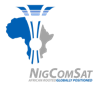 &nbsp;&nbsp; 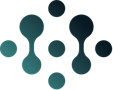

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-4/day-2-scikit-learn-and-isolation-forest/2-exercise/W4D2-exercise.ipynb)

# 🌲 Week 4 · Day 2: Meet scikit-learn + Isolation Forest

**Today:** you train your first machine-learning model. It looks at **six channels at once** and points at the hours that are hardest to explain. Then you check *why* it pointed, because rare is not the same as broken.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W4D2-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _res(x, caught, fa, tol=0):
    return isinstance(x, dict) and x.get("caught") == caught and abs(x.get("false_alarms", -999) - fa) <= tol

def _c_a1(x):
    return tuple(x) == (8760, 6), \
        "8,760 rows (hours) × 6 columns (channels). That's X. 🧮", \
        "Pick the six channel columns out of bus: bus[CHANNELS]"

def _c_a2(x):
    return int(x) == 5832, "5,832 training hours: 1 January to 31 August. The forest learns 'normal' from these.", \
        "Every hour BEFORE 1 September: TRAIN_END = \"2025-09-01\""

def _c_a3(x):
    return getattr(x, "contamination", None) == 0.005 and hasattr(x, "offset_"), \
        "Forest trained: 200 random trees, allowed to flag 0.5% of hours. 🌲", \
        "0.5% written as a fraction is 0.005. Then run the cell so model.fit() happens."

def _c_a4(x):
    return _near(x, 43.800, 0.6), "About 44 hours. Remember that number: it's your sanity check. ✅", \
        "contamination × number of hours: CONTAMINATION * len(X)"

def _c_a5(x):
    return _near(x, 58, 5), \
        "58 flags: the same ballpark as 44. If you had thousands, you'd know something was wrong.", \
        "predict() says -1 for odd and 1 for normal. Which one is a flag? (Thousands of flags = you picked the wrong one.)"

def _c_b1(x):
    return int(x) == 21, "21:00 UTC: eclipse time, every single flag. 🌘 The forest found the lifeguard.", \
        "Read the top of the value_counts() output: which hour of the day appears?"

def _c_b2(x):
    return _res(x, 1, 37, 5), \
        "Caught 1 of 5... Before you celebrate, look at WHICH event and WHEN in the next cell.", \
        "Score the forest's True/False flags: my_flags = flags_all"

def _c_b3(x):
    return x is False or str(x).strip().lower() == "false", \
        "Correct: a lucky catch. EV04 is an amplifier fault; every flag inside it was an eclipse hour. Right answer, wrong reason.", \
        "Look at the hours flagged inside EV04: all at 21:00. Is that the amplifier?"

def _c_c1(x):
    return int(x) == 4, "4 hours: this one and the 3 before it. Eclipse + 3 recharge hours are now 'not judged'. 🌞", \
        "Eclipse is one hour (21:00) and recharge is the next 3 (22, 23, 00). This hour + the 3 before = ?"

def _c_c2(x):
    return _res(x, 4, 16, 5), \
        "4 of 5, 16 false alarms, no eclipse flags. Big improvement. Now read the event table below. 👇", \
        "Fit on rows that are training AND steady sun: FIT_ROWS = train & steady"

def _c_c3(x):
    return _res(x, 4, 3), \
        "4 of 5 with only 3 false alarms, and it catches EV03. The old tool still bites. 📊", \
        "The classic control chart: K = 3"

def _c_c4(x):
    return "chart" in str(x).strip().lower(), "The chart! EV03's array current is 34σ low. A spike in ONE channel is the chart's home ground.", \
        "Compare the two event tables: which one has EV03 = True? Answer \"chart\" or \"forest\"."

def _c_d1(x):
    return int(x["eclipse"].max()) == 92 and int(x["recharge"].max()) == 276, \
        "Eclipse got its own cluster (92/92) and so did recharge (276/276). Nobody told it. 🧩", \
        "k-means measures distance, so scale first: SCALER = StandardScaler()"

def _c_d2(x):
    return str(x).strip() == "battery_soc_pct", "battery_soc_pct: state of charge -20.7σ in full sun. That's the sentence for the duty engineer.", \
        "Find the number furthest from zero (ignore the sign) and copy its column name, in quotes."

def _c_bonus(x):
    return isinstance(x, dict) and x.get("caught", 0) >= 2 and x.get("false_alarms", 99) <= 3, \
        "Strict and sure: only the battery-not-charging faults survive. The forest's most confident finds are EV02 and EV05. 🌶️🏆", \
        "Make contamination smaller (e.g. 0.002) until false alarms are 3 or fewer, while still catching 2 events."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "A5": _c_a5, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3,
          "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "C4": _c_c4, "D1": _c_d1, "D2": _c_d2, "BONUS": _c_bonus}
HINTS = {"D1": "Pass the crosstab table itself."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


▶️ Load a full year of hourly telemetry (six channels + the eclipse flag), the answer key, and the scikit-learn tools.
Colab already has scikit-learn installed.

In [ ]:
bus = pd.read_csv(data_path("bus_telemetry_multivariate_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
labels = load_labels("anomaly_labels_week5")

from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import sklearn

print("hours:", len(bus), "· eclipse hours:", int(bus["eclipse_flag"].sum()), "· scikit-learn", sklearn.__version__)
display(labels[["event_id", "start", "end", "type", "channels_involved"]])

---
# Part A: Your first forest (15 min) 🧰

scikit-learn always works the same way: **build X → make a model → `fit` → `predict`**.

### A1 ✍️ Build X
X is a table of numbers: **one row per hour, one column per channel**. Pick the six channels out of `bus`.

In [ ]:
CHANNELS = ["solar_array_current_a", "bus_voltage_v", "battery_soc_pct",
            "battery_temp_c", "twta_temp_c", "rf_drive_pct"]

X = ___

assert X is not None, "✍️ Fill in X first, then run this cell again."
print(X.shape)
check("A1", X.shape)

### A2 ✍️ The months it learns from
The forest learns what "normal" looks like from **January to August**: every hour *before* 1 September. Write that date as text, like `"2025-01-31"`.

In [ ]:
TRAIN_END = ___

assert TRAIN_END is not None, "✍️ Fill in TRAIN_END first."
train = bus.index < TRAIN_END
print("training hours:", train.sum(), "· from", bus.index[train][0], "to", bus.index[train][-1])
check("A2", int(train.sum()))

### A3 ✍️ Make the model and fit it
`contamination` is the share of hours you **allow** it to flag. We allow **0.5%**. Write it as a fraction.
`random_state=42` makes the random trees the same every time you run it (and the same as your neighbour's).

In [ ]:
CONTAMINATION = ___

assert CONTAMINATION is not None, "✍️ Fill in CONTAMINATION first."
model = IsolationForest(n_estimators=200, contamination=CONTAMINATION, random_state=42)
model.fit(X[train])          # no labels here: it only learns what is common
check("A3", model)

### A4 ✍️ Sanity check BEFORE you look
If you allow 0.5% of the year's hours, about how many flags should you expect? (Work it out from `CONTAMINATION` and `len(X)`.)

In [ ]:
expected_flags = ___

print("expect about", expected_flags, "flags")
check("A4", expected_flags)

### A5 ✍️ Ask it: which hours look odd?
`model.predict(X)` gives **1** for "looks normal" and **-1** for "looks odd". Which value is a flag?

In [ ]:
pred = model.predict(X)
print(pd.Series(pred).value_counts())

ODD = ___

assert ODD is not None, "✍️ Fill in ODD first."
flags_all = pd.Series(pred == ODD, index=X.index)
print("flagged hours:", flags_all.sum(), "· expected about", round(expected_flags))
check("A5", int(flags_all.sum()))

---
# Part B: What did it find? (15 min) 🔍

▶️ `decision_function` gives every hour a score. **Lower = more odd.** Here are the ten oddest hours of the year.

In [ ]:
score = pd.Series(model.decision_function(X), index=X.index)
score.nsmallest(10)

### B1 ✍️ What hour of the day are the flags?
▶️ The cell counts the flags by hour of day. Type the hour you see (a number, e.g. `9`).

In [ ]:
print(flags_all[flags_all].index.hour.value_counts())

flag_hour = ___

check("B1", flag_hour)

▶️ The **scorer** from Week 4 Day 1, with one extra helper. `score_events` uses the same 4 rules. `event_table` shows, for each event: caught or not, how many hours late the first flag was, and how many of the event's hours lit up.

In [ ]:
def score_events(flags, labels, tol="1h"):
    """Event-level scoring, the same 4 rules as Week 4 Day 1. flags: a True/False Series with a time index.
    Events that fall outside the hours being scored are skipped."""
    tol = pd.Timedelta(tol)
    n_events, caught, inside_any = 0, 0, pd.Series(False, index=flags.index)
    for _, ev in labels.iterrows():
        window = (flags.index >= ev["start"] - tol) & (flags.index <= ev["end"] + tol)
        if not window.any():
            continue                     # this event is not in the hours being scored
        n_events += 1
        if flags[window].any():          # one flag or many = ONE catch
            caught += 1
        inside_any |= window
    false_alarms = int((flags & ~inside_any).sum())
    alarms = caught + false_alarms
    return {"events": n_events, "caught": caught, "false_alarms": false_alarms,
            "recall": round(caught / n_events, 3) if n_events else float("nan"),
            "precision": round(caught / alarms, 3) if alarms else float("nan")}

def event_table(flags, labels):
    """One row per event: caught? how many hours late was the first flag? how many of its hours lit up?"""
    rows = []
    for _, ev in labels.iterrows():
        inside = (flags.index >= ev["start"]) & (flags.index <= ev["end"])
        if not inside.any():
            continue
        window = (flags.index >= ev["start"] - pd.Timedelta("1h")) & (flags.index <= ev["end"] + pd.Timedelta("1h"))
        hits = flags[window]
        first = hits[hits].index.min() if hits.any() else None
        rows.append({"event": ev["event_id"], "type": ev["type"], "caught": bool(hits.any()),
                     "hours_late": None if first is None else int((first - ev["start"]) / pd.Timedelta("1h")),
                     "hours_flagged": int(flags[inside].sum()), "hours_long": int(inside.sum())})
    return pd.DataFrame(rows).set_index("event").astype({"hours_late": "Int64"})

print("✅ score_events() and event_table() are ready")

### B2 ✍️ Score the forest
Which Series holds the forest's True/False flags?

In [ ]:
my_flags = ___

assert my_flags is not None, "✍️ Fill in my_flags first."
result_all = score_events(my_flags, labels)
print(result_all)
check("B2", result_all)

▶️ Before you celebrate: **which** event, and **when**? EV04 lasts four weeks. Look at what time of day its flags were.

In [ ]:
display(event_table(flags_all, labels))

in_ev04 = flags_all & (bus.index >= "2025-09-03") & (bus.index < "2025-10-01")
print("EV04 flags by hour of day:", in_ev04[in_ev04].index.hour.value_counts().to_dict())

### B3 ✍️ Real catch or lucky catch?
EV04 is an **amplifier** fault (cooling path). Every flag inside it came at eclipse time. Did the forest really see the amplifier problem? Answer `True` or `False` (no quotes).

In [ ]:
ev04_is_a_real_catch = ___

check("B3", ev04_is_a_real_catch)

---
# Part C: Give it context (15 min) 🌞

Eclipse (21:00) and the **3 recharge hours** after it are normal states with their own normal: NEPA takes light, then the inverter charges hard.
So we only fit on, and only judge, **steady sunlight**: no eclipse in this hour **or the 3 hours before it**.

### C1 ✍️ How long is the window?
This hour plus the 3 before it is a window of how many hours?

In [ ]:
window_hours = ___

check("C1", window_hours)

▶️ Here is the function. `rolling(4).max() == 0` means: the biggest eclipse_flag in the last 4 hours is 0, so no eclipse at all.

In [ ]:
def steady_sun(bus):
    """True in steady sunlight: no eclipse this hour or in the 3 hours before.
    Eclipse (battery power) and the 3 recharge hours after it are normal states with their own normal."""
    return bus["eclipse_flag"].rolling(4).max() == 0

steady = steady_sun(bus)
print("steady-sun hours:", steady.sum(), "· not judged:", (~steady).sum(), "(eclipse, recharge and the first 3 hours of the file)")

### C2 ✍️ The forest, steady sun only
Fit on rows that are **training AND steady sun** (`&` means "and"). Then keep only the flags in steady sun.

In [ ]:
model2 = IsolationForest(n_estimators=200, contamination=0.005, random_state=42)

FIT_ROWS = ___

assert FIT_ROWS is not None, "✍️ Fill in FIT_ROWS first."
model2.fit(X[FIT_ROWS])
flags_steady = pd.Series(model2.predict(X) == -1, index=X.index) & steady
result_steady = score_events(flags_steady, labels)
print(result_steady)
check("C2", result_steady)

▶️ Read the event table carefully: which one did it miss, and how late was EV04? Then: in which months are the false alarms?

In [ ]:
display(event_table(flags_steady, labels))

inside = pd.Series(False, index=bus.index)
for _, ev in labels.iterrows():
    inside |= (bus.index >= ev["start"] - pd.Timedelta("1h")) & (bus.index <= ev["end"] + pd.Timedelta("1h"))
false_alarms = flags_steady & ~inside
print("false alarms by month:", false_alarms[false_alarms].index.month.value_counts().sort_index().to_dict())

### C3 ✍️ The Week 3 control chart on the same hours
Same hours, same scorer, the old tool: mean ± **K** standard deviations per channel, from steady training hours. Use the classic **K**.

In [ ]:
HEALTH = ["solar_array_current_a", "bus_voltage_v", "battery_soc_pct", "battery_temp_c", "twta_temp_c"]
ref = bus.loc[train & steady, HEALTH]
z = (bus[HEALTH] - ref.mean()) / ref.std()

K = ___

assert K is not None, "✍️ Fill in K first."
chart_steady = (z.abs() > K).any(axis=1) & steady
result_chart = score_events(chart_steady, labels)
print(result_chart)
display(event_table(chart_steady, labels))
check("C3", result_chart)

### C4 ✍️ Who caught EV03?
EV03 is a 12 A drop in array current for one hour. Which detector caught it: `"forest"` or `"chart"`?

In [ ]:
catches_ev03 = ___

check("C4", catches_ev03)

---
# Part D: Clustering, and explaining a flag (10 min) 🧩

▶️ First, the **true** state of every hour (we only use it to *check* the clusters, never to make them).

In [ ]:
state = pd.Series(np.select([bus["eclipse_flag"] == 1, bus["eclipse_flag"].shift(1).rolling(3).max() == 1],
                             ["eclipse", "recharge"], "steady sun"), index=bus.index)
state.value_counts()

### D1 ✍️ Let k-means find the modes
k-means groups hours that are **close** to each other. Distance cares about units, so put a scaler in front of it. Which scikit-learn tool turns every column into "standard deviations from its mean"?

In [ ]:
SCALER = ___

assert SCALER is not None, "✍️ Fill in SCALER first."
km = make_pipeline(SCALER, KMeans(4, n_init=10, random_state=42))
cluster = km.fit_predict(X)
table = pd.crosstab(cluster, state)
display(table)
check("D1", table)

▶️ The same k-means **without** the scaler. Where did the recharge hours go?

In [ ]:
pd.crosstab(KMeans(4, n_init=10, random_state=42).fit_predict(X), state)

### D2 ✍️ Explain a flag
A score with no reason won't survive the duty engineer. ▶️ The cell shows each channel's **z-score** (how many standard deviations from steady training normal) for the first hour of EV02.
Which channel is furthest from normal? Copy its name, in quotes.

In [ ]:
ref6 = bus.loc[train & steady, CHANNELS]
z6 = (bus[CHANNELS] - ref6.mean()) / ref6.std()
print(z6.loc["2025-05-02 01:00"].round(1))

loudest_channel = ___

check("D2", loudest_channel)

---
## 🌶️ Pepper task: turn the dial
`contamination` is a dial. Turn it **down** and the forest only flags what it is surest about.
✍️ Find a contamination that keeps **3 or fewer** false alarms while still catching **at least 2** events (steady sun, same as C2). Which events survive?

In [ ]:
PEPPER_CONTAMINATION = ___

assert PEPPER_CONTAMINATION is not None, "✍️ Pick PEPPER_CONTAMINATION first."
m = IsolationForest(n_estimators=200, contamination=PEPPER_CONTAMINATION, random_state=42).fit(X[train & steady])
pepper_flags = pd.Series(m.predict(X) == -1, index=X.index) & steady
pepper_result = score_events(pepper_flags, labels)
print(pepper_result)
display(event_table(pepper_flags, labels))
check("BONUS", pepper_result)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **scikit-learn in 3 verbs:** build X (rows = hours, columns = channels) → `fit` → `predict` / `decision_function` (lower = more odd).
- **Sanity-check the count:** contamination 0.5% of ~8,760 hours ≈ 44 flags. Thousands = a bug.
- **Rare is not broken:** the raw forest flagged only eclipse hours. Its one "catch" was luck. Always check *which* hours and *why*.
- **Context first:** fitting and judging steady sunlight only removed every eclipse flag.
- **The old chart still wins some fights:** it caught EV03, the single-channel spike the forest missed.
- **k-means finds operating modes**, but only after scaling. The forest doesn't care about scaling.
- **Explain every flag** with z-scores: the biggest one is your sentence for the duty engineer.

**Next time:** *Give the model eyes*: one new column makes EV04 light up. 👀

<sub>Data: synthetic teaching dataset from the original Week 5 code book (`Time-series/week-05`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>